# IND320 Project Part 4 – Prediction, maps and app refactoring
## Norwegian reservoirs, weather, electricity and exchange rates

**Author:** Daniar Omar

This notebook completes the project with exchange rates from Norges Bank, an investigation of timezones across the four data sources, forecasting of reservoir filling with the River framework (SARIMAX and a lag-based machine learning model) and a sliding window correlation between weather and reservoir filling. The Streamlit app was refactored (theme, Plotly, grouped navigation) and extended with an interactive map, correlation and forecasting pages.

**GitHub:** https://github.com/dano22222/dano22222 (Part 4 is developed in the branch `part4-development`)

**Streamlit application (same app as Parts 1–3):** https://dano22222-u9jpvjhwntlcuukcush85v.streamlit.app/

**Screencast of the assignment:** ADD SCREENCAST LINK HERE

## 1. Environment and configuration

All reusable code lives in the `src/` package, so this notebook and the Streamlit app use the same functions. New in Part 4: `src/currency.py` (Norges Bank), daily weather in `src/weather.py`, `src/forecast.py` (River), `src/correlation.py`, `src/plots.py` and `src/theme.py` (Plotly figures and theme for the app) and `src/maps.py` (Folium map).

In [1]:
#locate the project from either the root or the notebooks folder
from pathlib import Path
import sys, json, time, importlib.metadata, warnings
from io import StringIO
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

#data handling and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from IPython.display import display, Markdown, Image

#project modules
from src.reservoir import weekly_series
from src.currency import fetch_exchange_rates, parse_exchange_csv, weekly_rates, URL as NB_URL
from src.weather import (download_daily_sample, weekly_weather, latest_era5_date, load_region,
                         DAILY_VARIABLES, WEATHER_LABELS)
from src.forecast import forecast_filling, backtest, seasonal_naive, DEFAULTS, _week
from src.correlation import sliding_correlation, lag_scan

#river warns about pandas internals in some versions; the warnings do not affect the results
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})
for package in ["pandas", "numpy", "river", "plotly", "streamlit", "folium", "requests"]:
    print(f"{package:10s} {importlib.metadata.version(package)}")

pandas     3.1.0
numpy      2.4.6
river      0.27.0
plotly     7.1.0
streamlit  1.66.1
folium     1.0.0
requests   2.34.2


## 2. Structure and navigation of the app (sketch)

Before changing the code, the new elements were listed and grouped by the *type of task*. The sketch below was drawn first (the figure is generated by `scripts/make_navigation_sketch.py` so it stays in sync with the repository). The sidebar uses `st.navigation` with four groups:

| Group | Pages | Purpose |
|---|---|---|
| **Start** | Overview, Map and selection | front page with links to all groups; the map sets the global area and time frame |
| **Explore** | Data overview, Reservoir plots, Electricity flows | one view per data source (NVE, Norges Bank, ENTSO-E/MongoDB) |
| **Anomalies** | Weather SATV and LOF, STL and spectrogram | outliers, anomalies and seasonal structure (Part 3) |
| **Predict** | Weather correlation, Forecast filling | relations between sources and forecasting |

Every page starts with a coloured band in the colour of its group, so the active group is always visible. The former `LineChartColumn` page was not removed but joined with the other plain data views (reservoir table and exchange rates) on the *Data overview* page, where the sparklines give a compact overview of all areas.

**Global vs local selections.** The area (sidebar, or a click on the map), the weather property (temperature by default) and the map time frame are stored in `st.session_state` under normal keys and follow the user between pages. Year, window lengths, lags and model parameters are local to the page where they are used.

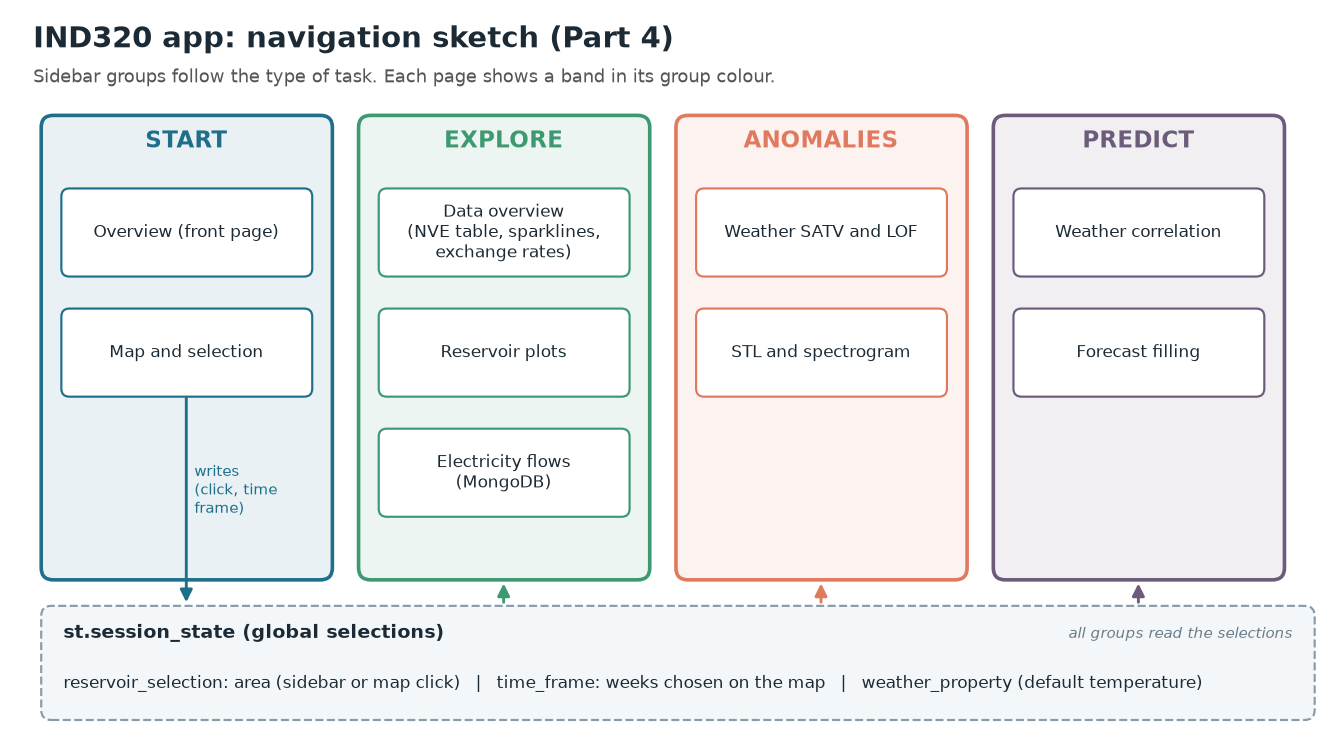

In [2]:
#the navigation sketch made before the refactoring
display(Image(filename=str(ROOT / "notebooks/figures/navigation_sketch.png"), width=900))

## 3. Exchange rates from Norges Bank

`fetch_exchange_rates(start, end, currencies=("EUR", "USD"))` calls the Norges Bank SDMX API (`https://data.norges-bank.no/api/data/EXR/B.EUR+USD.NOK.SP`) in CSV format. The answer has one row per currency and business day. The parser keeps the codes `BASE_CUR`, `TIME_PERIOD`, `OBS_VALUE` and `UNIT_MULT` (rates for e.g. JPY are per 100 units), accepts both decimal points and decimal commas, and returns one column per currency in NOK per unit. `weekly_rates()` averages the daily rates over the same Sunday-ending weeks as the reservoir statistics, which is the form used as an exogenous variable in the forecasts.

business days: 4252 | first: 2010-01-04 | last: 2026-11-20


,EUR,USD
date,,
2026-11-16,10.5740,9.6005
2026-11-17,10.5755,9.6237
2026-11-18,10.6045,9.6686
2026-11-19,10.6475,9.6866
2026-11-20,10.7180,9.7525


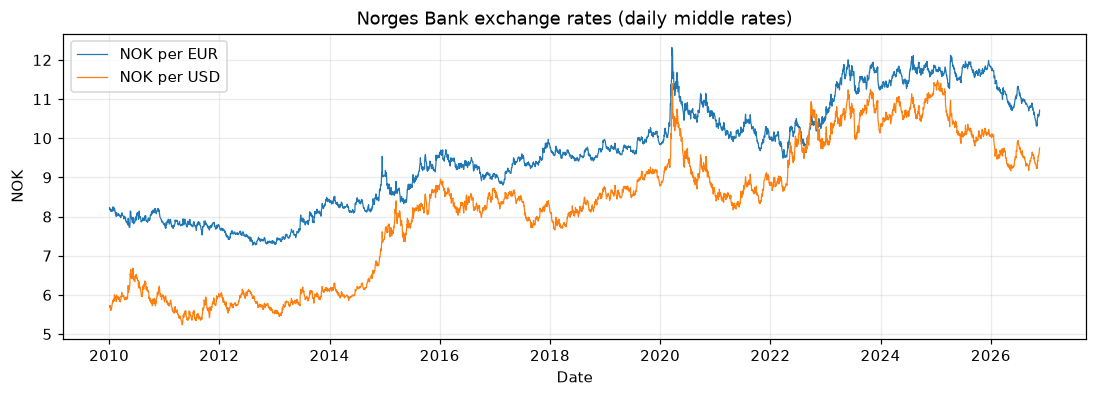

In [3]:
#download euro and us dollar rates from 2010 until today (requires internet access)
END_TODAY = pd.Timestamp.now(tz="Europe/Oslo").date()
rates = fetch_exchange_rates("2010-01-01", END_TODAY)
print("business days:", len(rates), "| first:", rates.index.min().date(), "| last:", rates.index.max().date())
display(rates.tail())

#daily rates and their weekly means (nve weeks ending on sunday)
weekly_currency = weekly_rates(rates)
fig, ax = plt.subplots(figsize=(12, 3.6))
for column in rates.columns:
    ax.plot(rates.index, rates[column], lw=.8, label=f"NOK per {column}")
ax.set(title="Norges Bank exchange rates (daily middle rates)", ylabel="NOK", xlabel="Date")
ax.legend()
plt.show()

#a small check: no weekends in the data, and the weekly table has sunday dates
assert (rates.index.day_of_week < 5).all()
assert (weekly_currency.index.day_of_week == 6).all()

## 4. Timezones in Magasinstatistikk, ENTSO-E, Open-Meteo and Norges Bank

The four sources describe time in different ways. Joining them without care can shift values by one or two hours, which moves observations to a neighbouring day, week, month or year.

In [4]:
#nve magasinstatistikk: the date column is a plain date (no time, no timezone)
reservoir = pd.read_parquet(ROOT / "data/reservoir.parquet")
print("weekday of the dates:", reservoir.date.dt.day_name().value_counts().to_dict())
#the date is the sunday that ends the iso week given in the year and week columns
iso = reservoir.date.dt.isocalendar()
print("date matches iso year and week:", bool(((iso.year == reservoir.year) & (iso.week == reservoir.week)).all()))
print("publication time example:", reservoir["neste_Publiseringsdato"].iloc[-1], "(no offset given: Norwegian local time)")

weekday of the dates: {'Sunday': 14940}
date matches iso year and week: True
publication time example: 2026-11-04T13:00:00 (no offset given: Norwegian local time)


In [5]:
#entso-e: all period starts and ends in the xml are utc ("z"); part 2 kept utc through spark, cassandra and mongodb.
#the year and month fields in mongodb were derived from the utc time, so the first hour(s) of a norwegian
#month or year end up in the previous one
examples = pd.to_datetime(["2024-12-31T23:00:00Z", "2025-03-31T22:15:00Z", "2025-10-26T00:30:00Z"], utc=True)
check = pd.DataFrame({"utc": examples, "oslo": examples.tz_convert("Europe/Oslo")})
check["utc month"] = check.utc.dt.strftime("%Y-%m")
check["oslo month"] = check.oslo.dt.strftime("%Y-%m")
display(check)

#oslo is utc+1 in winter and utc+2 in summer; the dst change days have 23 and 25 hours
for day in ["2025-03-30", "2025-10-26"]:
    hours = pd.date_range(day, pd.Timestamp(day) + pd.Timedelta(days=1), freq="h", tz="Europe/Oslo", inclusive="left")
    print(day, "has", len(hours), "local hours")

,utc,oslo,utc month,oslo month
0,2024-12-31 23:00:00+00:00,2025-01-01 00:00:00+01:00,2024-12,2025-01
1,2025-03-31 22:15:00+00:00,2025-04-01 00:15:00+02:00,2025-03,2025-04
2,2025-10-26 00:30:00+00:00,2025-10-26 02:30:00+02:00,2025-10,2025-10


2025-03-30 has 23 local hours
2025-10-26 has 25 local hours


In [6]:
#open-meteo: the api returns local time for the "timezone" parameter. part 3 used utc for hourly data,
#which avoids missing/duplicate hours at the dst changes. daily sums, however, depend on where a day starts.
#the saved no3 2024 hourly mean (utc) shows the difference between utc days and norwegian days
hourly, _ = load_region("NO3")
utc_days = hourly.precipitation.resample("D").sum()
oslo_days = hourly.precipitation.tz_convert("Europe/Oslo").resample("D").sum()
oslo_days.index = oslo_days.index.tz_localize(None)
utc_days.index = utc_days.index.tz_localize(None)
difference = (oslo_days - utc_days).dropna()
print(f"days where the daily precipitation differs by more than 0.5 mm: {(difference.abs() > .5).sum()} of {len(difference)}")
print(f"largest difference for one day: {difference.abs().max():.2f} mm")
#weekly sums on sunday ending weeks are less sensitive, but still differ at the week borders
weekly_difference = (hourly.precipitation.tz_convert("Europe/Oslo").resample("W-SUN").sum().values[1:-1]
                     - hourly.precipitation.resample("W-SUN").sum().values[1:-1])
print(f"largest weekly difference: {np.abs(weekly_difference).max():.2f} mm")

days where the daily precipitation differs by more than 0.5 mm: 98 of 366
largest difference for one day: 2.86 mm
largest weekly difference: 1.13 mm


In [7]:
#norges bank: one rate per norwegian business day. the csv contains a collection indicator that tells when
#the rate is observed; the dates themselves have no time and are norwegian calendar dates
raw = requests.get(NB_URL.format(currencies="EUR"), params={"format": "csv", "startPeriod": "2025-01-01",
                                                              "endPeriod": "2025-01-10", "locale": "en"}, timeout=30)
raw_table = pd.read_csv(StringIO(raw.text), sep=None, engine="python")
print([c for c in raw_table.columns][:20])
label_columns = [c for c in raw_table.columns if "ollection" in c or "Frequency" in c]
display(raw_table[label_columns + ["TIME_PERIOD", "OBS_VALUE"]].head(3))

['FREQ', 'Frequency', 'BASE_CUR', 'Base Currency', 'QUOTE_CUR', 'Quote Currency', 'TENOR', 'Tenor', 'DECIMALS', 'CALCULATED', 'UNIT_MULT', 'Unit Multiplier', 'COLLECTION', 'Collection Indicator', 'TIME_PERIOD', 'OBS_VALUE']


,Frequency,Collection Indicator,TIME_PERIOD,OBS_VALUE
0,Business,ECB concertation time 14:15 CET,2025-01-02,11.7173
1,Business,ECB concertation time 14:15 CET,2025-01-03,11.7130
2,Business,ECB concertation time 14:15 CET,2025-01-06,11.7095


**Findings and solutions**

| Source | How time is given | Risk | Solution in the project |
|---|---|---|---|
| NVE Magasinstatistikk | a date (Sunday) that ends the ISO week, Norwegian calendar, no time or offset | none inside the source, but other data must use the same weeks | the NVE week (`W-SUN`, Europe/Oslo calendar) is the common time axis for all joins |
| ENTSO-E (Part 2, MongoDB) | timestamps in UTC (`Z`); year/month in MongoDB were derived from UTC | the first 1–2 hours of a Norwegian month/year are counted in the previous one | timestamps stay in UTC in storage; the app no longer uses the stored UTC `year` field but queries the UTC limits of the Norwegian calendar year (1 January 00:00 Oslo time = 31 December 23:00 UTC), converts to Europe/Oslo and filters months in Oslo time; weekly sums are made by MongoDB with `$dateTrunc(..., timezone: "Europe/Oslo")` |
| Open-Meteo (ERA5) | local time of the requested `timezone`; Part 3 used UTC for hourly data | daily and weekly aggregates shift by 1–2 hours (see the precipitation example above); local hourly series have 23/25-hour days | hourly analyses keep UTC (no DST gaps); daily data for Part 4 are requested with `timezone=Europe/Oslo`, so days and weeks match NVE |
| Norges Bank | business-day dates (no weekend/holiday rows), observed in the afternoon Norwegian time (collection indicator) | missing days and day boundaries | dates are used as Norwegian dates; weekly means over the NVE weeks (`weekly_rates`) |

In short: keep UTC where exact hours matter (hourly weather, electricity storage), and convert to Europe/Oslo **before** aggregating to days or weeks, so all sources end up on the same Sunday-ending NVE weeks.

## 5. Forecasting reservoir filling with River

`forecast_filling(target, exog=None, train_end=None, history_years=10, horizon=26, resolution="W", future="climatology", **parameters)` in `src/forecast.py`:

- **Target:** the weekly filling fraction of one Magasinstatistikk area (handled in percent).
- **Models** (`model=`):
  - `"snarimax"` – `river.time_series.SNARIMAX(p, d, q, m, sp, sd, sq)` with a scaled `LinearRegression` as regressor; exogenous variables are passed as `x` in `learn_one` and as `xs` in `forecast`.
  - `"lags"` – a lag-based ML model: a River `StandardScaler | LinearRegression` trained online on the last weekly changes (`lags`), optionally the change one year earlier (`seasonal_lag`), the average change for the week of the year in the training data, two seasonal harmonics and the exogenous variables. It predicts the next change and is applied recursively.
- **Dynamic forecasting:** after the training period both models only see their own predictions.
- **Inputs:** model parameters, history length (`history_years`), horizon, time resolution (`"W"`, `"2W"`, `"4W"`) and the selection of exogenous data sources as a dictionary, e.g. `{"weather": weekly_weather_table, "currency": weekly_rates_table, "electricity": net_export_table}`.
- **Unknown future exogenous values:** weather and electricity use the average for the same week in the training data (climatology), exchange rates keep their last value (persistence). `future="observed"` uses measured values when available (a perfect-forecast upper bound).
- **Prediction intervals (bonus):** two extra models trained with `optim.losses.Quantile(alpha)` give the lower and upper limits (default 90 %).

`backtest()` trains and forecasts from twelve training end dates, 13 weeks apart, over the last three years with known outcome, so every season is used as a start three times. The horizon is given in weeks for every resolution, and a backtest only accepts forecasts whose whole horizon has been observed. The mean absolute error (MAE) is in percentage points of filling. Two simple references are included: *seasonal naive* (the filling one year earlier) and *normal change* (the last value plus the average weekly change for the coming weeks of the year).

settings: {'model': 'lags', 'lags': 1, 'learning_rate': 0.003, 'epochs': 3, 'history_years': 10}
scores: {'mae': 7.38, 'rmse': 8.46, 'weeks_compared': 26, 'coverage': 1.0} | 0.09 s


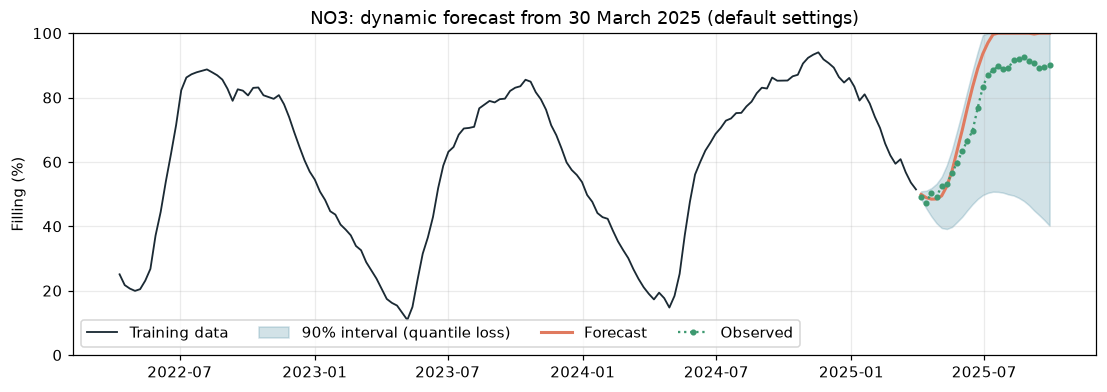

In [8]:
#the three test areas: the price area no3 (main example), no2 (largest storage) and the eastern water area
AREAS = {"EL 3 (NO3)": ("EL", 3), "EL 2 (NO2)": ("EL", 2), "VASS 1": ("VASS", 1)}
series = {name: weekly_series(reservoir, *area) for name, area in AREAS.items()}
filling = series["EL 3 (NO3)"]
HORIZON = 26


def reference_scores(target, horizon=HORIZON):
    """mae of the seasonal naive and the normal change references for the same twelve origins as backtest()."""
    last = target.index.max() - pd.Timedelta(weeks=horizon)
    naive, normal = [], []
    for origin in pd.date_range(end=last, periods=12, freq="13W"):
        origin = target.index[target.index <= origin].max()
        truth = (target * 100).loc[origin:].iloc[1:horizon + 1]
        naive.append((seasonal_naive(target, origin, horizon) - truth).abs().mean())
        history = (target * 100).loc[origin - pd.Timedelta(days=3652):origin]
        changes = history.diff().dropna()
        mean_change = changes.groupby(_week(changes.index)).mean()
        prediction = history.iloc[-1] + np.cumsum(mean_change.reindex(_week(truth.index)).to_numpy())
        normal.append(np.abs(prediction - truth.to_numpy()).mean())
    return {"seasonal naive": np.mean(naive), "normal change": np.mean(normal)}


#one forecast with the default settings, trained until spring 2025 so the result can be compared with the truth
example = forecast_filling(filling, train_end="2025-03-30", horizon=HORIZON)
print("settings:", {k: example.settings[k] for k in ["model", "lags", "learning_rate", "epochs", "history_years"]})
print("scores:", {k: round(v, 2) for k, v in example.scores().items()}, f"| {example.seconds:.2f} s")


def plot_forecast(result, title):
    """matplotlib version of the forecast plot used in the app (plotly there)."""
    fig, ax = plt.subplots(figsize=(12, 3.8))
    history = result.history.iloc[-156:]
    ax.plot(history.index, history.values, color="#1B2A34", lw=1.2, label="Training data")
    ax.fill_between(result.forecast.index, result.forecast.lower, result.forecast.upper, color="#1F6F8B", alpha=.2,
                    label=f"{result.settings['interval']:.0%} interval (quantile loss)")
    ax.plot(result.forecast.index, result.forecast.forecast, color="#E07A5F", lw=2, label="Forecast")
    ax.plot(result.actual.index, result.actual.values, color="#3D9970", ls=":", marker=".", label="Observed")
    ax.set(title=title, ylabel="Filling (%)", ylim=(0, 100))
    ax.legend(loc="lower left", ncol=4)
    plt.show()


plot_forecast(example, "NO3: dynamic forecast from 30 March 2025 (default settings)")

### 5.1 Time resolution

NVE publishes one value per week, so weekly is the finest *real* resolution; a daily series would only interpolate between the weekly values and multiply the computation time by seven without new information. The function was also tested on coarser resolutions (means over two and four weeks, seasonal period 26 and 13). The horizon is given in weeks in all cases (26 weeks = 13 two-week or 7 four-week periods), and all resolutions use the same twelve training end dates with fully observed horizons, so the errors are comparable. The error is measured on the resolution of the forecast itself.

In [9]:
#same model, three resolutions, the same twelve origins and the same 26 week horizon
#(26 weekly, 13 two week or 7 four week periods); time per forecast covers three models: forecast, lower, upper
rows = []
for name, target in series.items():
    for resolution in ["W", "2W", "4W"]:
        table = backtest(target, horizon=HORIZON, resolution=resolution)
        rows.append({"area": name, "resolution": resolution, "mae": table.attrs["mean"]["mae"],
                     "coverage": table.attrs["mean"]["coverage"], "seconds per forecast": table.seconds.mean()})
resolution_table = pd.DataFrame(rows)
display(resolution_table.pivot(index="resolution", columns="area", values=["mae", "seconds per forecast"]).round(3))

mae                   seconds per forecast                  
area       EL 2 (NO2) EL 3 (NO3) VASS 1           EL 2 (NO2) EL 3 (NO3) VASS 1
resolution                                                                    
2W              7.097      8.143  7.867                0.031      0.029  0.037
4W              7.252      8.447  8.039                0.017      0.016  0.019
W               6.499      8.639  7.169                0.048      0.087  0.053

### 5.2 Model type and parameters

A grid of settings for both model types was tested on the three areas with the same twelve backtest origins. For SNARIMAX the seasonal period is one year (m = 52 weeks).

In [10]:
#candidate settings (the rest of the parameters keep their defaults)
candidates = {
    "SNARIMAX (1,1,0)(0,0,0)": dict(model="snarimax", p=1, d=1, q=0, sp=0, sd=0, sq=0, learning_rate=.01),
    "SNARIMAX (2,1,0)(1,0,0)": dict(model="snarimax", p=2, d=1, q=0, sp=1, sd=0, sq=0, learning_rate=.01),
    "SNARIMAX (2,1,0)(1,1,0)": dict(model="snarimax", p=2, d=1, q=0, sp=1, sd=1, sq=0, learning_rate=.01),
    "SNARIMAX (2,1,0)(1,1,0) lr .003": dict(model="snarimax", p=2, d=1, q=0, sp=1, sd=1, sq=0, learning_rate=.003),
    "SNARIMAX (2,1,0)(1,1,1)": dict(model="snarimax", p=2, d=1, q=0, sp=1, sd=1, sq=1, learning_rate=.01),
    "SNARIMAX (2,0,0)(1,1,0)": dict(model="snarimax", p=2, d=0, q=0, sp=1, sd=1, sq=0, learning_rate=.01),
    "Lags 3 + last year, lr .01, 1 pass": dict(model="lags", lags=3, seasonal_lag=True, learning_rate=.01, epochs=1),
    "Lags 3 + last year, lr .003, 3 passes": dict(model="lags", lags=3, seasonal_lag=True, learning_rate=.003, epochs=3),
    "Lags 3, lr .003, 3 passes": dict(model="lags", lags=3, seasonal_lag=False, learning_rate=.003, epochs=3),
    "Lags 1, lr .003, 3 passes": dict(model="lags", lags=1, seasonal_lag=False, learning_rate=.003, epochs=3),
    "Lags 1, lr .001, 5 passes": dict(model="lags", lags=1, seasonal_lag=False, learning_rate=.001, epochs=5),
}
rows = []
started = time.perf_counter()
for name, target in series.items():
    for label, value in reference_scores(target).items():
        rows.append({"setting": f"Reference: {label}", "area": name, "mae": value})
    for label, settings in candidates.items():
        table = backtest(target, horizon=HORIZON, **settings)
        rows.append({"setting": label, "area": name, **table.attrs["mean"]})
grid = pd.DataFrame(rows)
print(f"grid finished in {time.perf_counter() - started:.0f} s")
summary = grid.pivot(index="setting", columns="area", values="mae")
summary["mean MAE"] = summary.mean(axis=1)
summary["mean coverage"] = grid.groupby("setting").coverage.mean()
display(summary.sort_values("mean MAE").round(2))

grid finished in 12 s


area,EL 2 (NO2),EL 3 (NO3),VASS 1,mean MAE,mean coverage
setting,,,,,
"Lags 1, lr .001, 5 passes",6.26,8.37,6.68,7.10,0.79
"Lags 1, lr .003, 3 passes",6.50,8.64,7.17,7.44,0.93
"Lags 3, lr .003, 3 passes",6.47,8.73,7.31,7.50,0.93
"Lags 3 + last year, lr .003, 3 passes",6.50,8.60,7.43,7.51,0.91
Reference: normal change,6.72,9.44,7.35,7.84,NaN
"Lags 3 + last year, lr .01, 1 pass",7.78,10.14,9.36,9.10,0.90
"SNARIMAX (2,1,0)(1,1,1)",8.65,11.58,9.11,9.78,0.92
"SNARIMAX (2,1,0)(1,1,0) lr .003",8.85,11.71,9.59,10.05,0.53
"SNARIMAX (2,1,0)(1,1,0)",10.01,11.88,10.98,10.96,0.88


### 5.3 Length of the training history

In [11]:
#the best lag model with 3 to 30 years of history
rows = []
for name, target in series.items():
    for years in [3, 5, 10, 20, 30]:
        table = backtest(target, horizon=HORIZON, history_years=years)
        rows.append({"area": name, "history (years)": years, "mae": table.attrs["mean"]["mae"],
                     "coverage": table.attrs["mean"]["coverage"], "seconds": table.seconds.mean()})
history_table = pd.DataFrame(rows)
display(history_table.pivot(index="history (years)", columns="area", values=["mae", "coverage"]).round(2))

mae                     coverage                  
area            EL 2 (NO2) EL 3 (NO3) VASS 1 EL 2 (NO2) EL 3 (NO3) VASS 1
history (years)                                                          
3                     7.91       9.07   8.26       0.56       0.49   0.50
5                     6.68       8.94   7.17       0.74       0.58   0.67
10                    6.50       8.64   7.17       0.94       0.93   0.93
20                    6.47       8.63   6.99       0.98       1.00   0.99
30                    6.59       8.70   7.08       0.99       1.00   0.99

### 5.4 Exogenous variables

Weather is downloaded as daily ERA5 aggregates for three of the 1000 sampled locations per region (days in Europe/Oslo time) and aggregated to the NVE weeks; precipitation, rain and snowfall are weekly sums, temperature and wind weekly means. Exchange rates are weekly means. The daily weather is cached in `data/weather/daily/` (not in Git) so the notebook does not use the Open-Meteo quota twice. Electricity flows (NO2–DK1 in MongoDB) only start in October 2024, which is too short for twelve backtest origins, so they are supported by the function and the app but not included in this comparison.

In [12]:
#daily weather for the test regions, cached on disk after the first download (about 940 call units per region).
#download_daily_sample splits the period into yearly requests and pauses to respect the open meteo limit per minute
DAILY_DIR = ROOT / "data/weather/daily"
DAILY_DIR.mkdir(parents=True, exist_ok=True)
WEATHER_START, WEATHER_END = "2014-01-01", str(latest_era5_date().date())


def cached_daily(region, start=WEATHER_START, end=WEATHER_END, n_points=3):
    """daily regional mean from open-meteo, stored as parquet so reruns need no new download."""
    path = DAILY_DIR / f"{region}_{start}_{end}_{n_points}.parquet"
    if path.exists():
        return pd.read_parquet(path)
    daily = download_daily_sample(region, start, end, n_points)
    daily.to_parquet(path)
    return daily


REGIONS = {"EL 3 (NO3)": "NO3", "EL 2 (NO2)": "NO2", "VASS 1": "VASS1"}
weekly_weather_tables = {name: weekly_weather(cached_daily(region)) for name, region in REGIONS.items()}
print({name: table.shape for name, table in weekly_weather_tables.items()})
display(weekly_weather_tables["EL 3 (NO3)"].describe().T.round(2))

{'EL 3 (NO3)': (673, 5), 'EL 2 (NO2)': (673, 5), 'VASS 1': (673, 5)}


,count,mean,std,min,25%,50%,75%,max
temperature_2m_mean,671.0,1.56,7.30,-19.8,-3.55,0.75,7.87,19.55
precipitation_sum,671.0,30.78,24.04,0.0,12.25,26.67,44.58,158.10
rain_sum,671.0,18.08,19.05,0.0,1.47,11.27,29.68,87.07
snowfall_sum,671.0,9.19,12.96,0.0,0.00,2.78,14.33,73.85
wind_speed_10m_max,671.0,11.57,2.06,6.6,10.15,11.44,12.89,20.97


In [13]:
#the default lag model with different exogenous sources; the history starts with the weather data in 2014
exog_options = {
    "none": lambda name: None,
    "weather: temperature + precipitation": lambda name: {"weather": weekly_weather_tables[name][["temperature_2m_mean", "precipitation_sum"]]},
    "weather: temperature + precipitation + snowfall": lambda name: {"weather": weekly_weather_tables[name][["temperature_2m_mean", "precipitation_sum", "snowfall_sum"]]},
    "currency: EUR + USD": lambda name: {"currency": weekly_currency},
    "weather (T + P) + currency": lambda name: {"weather": weekly_weather_tables[name][["temperature_2m_mean", "precipitation_sum"]],
                                                "currency": weekly_currency},
}
rows = []
for name, target in series.items():
    for label, make in exog_options.items():
        for future in ["climatology", "observed"]:
            if label == "none" and future == "observed":
                continue
            table = backtest(target.loc["2014":], make(name), horizon=HORIZON, future=future)
            rows.append({"exogenous": label, "future values": future, "area": name, **table.attrs["mean"]})
exog_table = pd.DataFrame(rows)
exog_summary = exog_table.pivot_table(index=["exogenous", "future values"], columns="area", values="mae")
exog_summary["mean MAE"] = exog_summary.mean(axis=1)
display(exog_summary.sort_values("mean MAE").round(2))

area                                                           EL 2 (NO2)  \
exogenous                                       future values               
weather (T + P) + currency                      observed             3.88   
weather: temperature + precipitation            observed             4.48   
weather: temperature + precipitation + snowfall observed             4.78   
                                                climatology          6.11   
weather: temperature + precipitation            climatology          6.05   
weather (T + P) + currency                      climatology          6.51   
none                                            climatology          6.50   
currency: EUR + USD                             observed             7.61   
                                                climatology          8.00   

area                                                           EL 3 (NO3)  \
exogenous                                       future values               
weather (T + P) + currency                      observed             5.20   
weather: temperature + precipitation            observed             5.59   
weather: temperature + precipitation + snowfall observed             5.76   
                                                climatology          7.90   
weather: temperature + precipitation            climatology          7.98   
weather (T + P) + currency                      climatology          7.10   
none                                            climatology          8.63   
currency: EUR + USD                             observed            10.01   
                                                climatology          9.95   

area                                                           VASS 1  \
exogenous                                       future values           
weather (T + P) + currency                      observed         7.00   
weather: temperature + precipitation            observed         6.31   
weather: temperature + precipitation + snowfall observed         6.69   
                                                climatology      6.93   
weather: temperature + precipitation            climatology      7.02   
weather (T + P) + currency                      climatology      7.69   
none                                            climatology      7.18   
currency: EUR + USD                             observed         8.36   
                                                climatology      8.56   

area                                                           mean MAE  
exogenous                                       future values            
weather (T + P) + currency                      observed           5.36  
weather: temperature + precipitation            observed           5.46  
weather: temperature + precipitation + snowfall observed           5.74  
                                                climatology        6.98  
weather: temperature + precipitation            climatology        7.02  
weather (T + P) + currency                      climatology        7.10  
none                                            climatology        7.44  
currency: EUR + USD                             observed           8.66  
                                                climatology        8.83

### 5.5 Results and default setting

In [14]:
#summarise the tests in text from the computed tables
#selection rule: lowest mean mae among the settings whose 90 % interval covers 80 to 97 % of the true values
models = summary.drop(index=[i for i in summary.index if i.startswith("Reference")])
calibrated = models[models["mean coverage"].between(.8, .97)]
best_setting = (calibrated if len(calibrated) else models).sort_values("mean MAE").iloc[0]
lowest_mae = models.sort_values("mean MAE").iloc[0]
weekly_mae = resolution_table.groupby("resolution").mae.mean()
weekly_coverage = resolution_table.groupby("resolution").coverage.mean()
history_mae = history_table.groupby("history (years)").mae.mean()
exog_mean = exog_summary["mean MAE"]
best_exog = exog_mean.idxmin()
none_mae = exog_mean.loc[("none", "climatology")]
#a real forecast does not know the future weather, so the default is chosen among the climatology rows
realistic = exog_mean.xs("climatology", level="future values")
best_realistic = realistic.idxmin()
display(Markdown(f"""
* **Resolution:** mean MAE {weekly_mae['W']:.1f} (weekly), {weekly_mae['2W']:.1f} (two weeks) and {weekly_mae['4W']:.1f} (four weeks) percentage points, with interval coverage {weekly_coverage['W']:.0%}, {weekly_coverage['2W']:.0%} and {weekly_coverage['4W']:.0%}.
One forecast with three models takes about {resolution_table.loc[resolution_table.resolution == 'W', 'seconds per forecast'].mean():.2f} s at weekly resolution, so speed is no reason to aggregate.
{"Weekly data also give the lowest error." if weekly_mae.idxmin() == "W" else f"Coarser periods ({weekly_mae.idxmin()}) give a slightly lower error, partly because averages over several weeks are smoother and easier to hit, but they show less detail and their intervals cover the truth less often."}
Weekly is therefore kept as the default: it is the native NVE resolution, fast, and keeps the most information.
* **Model:** the lowest error overall has *{lowest_mae.name}* (MAE {lowest_mae['mean MAE']:.1f}, interval coverage {lowest_mae['mean coverage']:.0%}).
Among the settings whose 90 % interval is reasonably calibrated (coverage 80–97 %), the best is *{best_setting.name}* with a mean MAE of {best_setting['mean MAE']:.1f} percentage points over 26 weeks and coverage {best_setting['mean coverage']:.0%}
(seasonal naive: {summary.loc['Reference: seasonal naive', 'mean MAE']:.1f}, normal change: {summary.loc['Reference: normal change', 'mean MAE']:.1f}).
The best SNARIMAX reaches {summary[summary.index.str.startswith('SNARIMAX')]['mean MAE'].min():.1f}. Seasonal differencing (D = 1) was essential for SNARIMAX; without it the forecasts drift away from the seasonal cycle.
A low learning rate with a few passes gave the most stable lag model; larger rates made the online SGD noisy, and the quantile models then covered too much or too little.
* **History:** mean MAE {', '.join(f'{y} years: {v:.1f}' for y, v in history_mae.items())}. Three to five years are too few to learn the seasonal pattern, and more than ten years adds little.
* **Exogenous variables:** without exogenous data the mean MAE is {none_mae:.1f} (history from 2014, like the weather data).
With estimated future values (weekly normal weather, last known exchange rate), which is what a real forecast can use, the best option is *{best_realistic}* with {realistic.min():.1f}.
With observed future values the best option is *{best_exog[0]}* ({exog_mean.min():.1f}); this is a best case that assumes a perfect weather forecast, and it shows that the weather of the coming weeks explains much of the remaining error.
Exchange rates alone made the forecasts worse ({realistic.loc["currency: EUR + USD"]:.1f}); they are not related to the inflow, so the model mostly learns noise from them.
"""))


* **Resolution:** mean MAE 7.4 (weekly), 7.7 (two weeks) and 7.9 (four weeks) percentage points, with interval coverage 93%, 55% and 51%.
One forecast with three models takes about 0.06 s at weekly resolution, so speed is no reason to aggregate.
Weekly data also give the lowest error.
Weekly is therefore kept as the default: it is the native NVE resolution, fast, and keeps the most information.
* **Model:** the lowest error overall has *Lags 1, lr .001, 5 passes* (MAE 7.1, interval coverage 79%).
Among the settings whose 90 % interval is reasonably calibrated (coverage 80–97 %), the best is *Lags 1, lr .003, 3 passes* with a mean MAE of 7.4 percentage points over 26 weeks and coverage 93%
(seasonal naive: 12.2, normal change: 7.8).
The best SNARIMAX reaches 9.8. Seasonal differencing (D = 1) was essential for SNARIMAX; without it the forecasts drift away from the seasonal cycle.
A low learning rate with a few passes gave the most stable lag model; larger rates made the online SGD noisy, and the quantile models then covered too much or too little.
* **History:** mean MAE 3 years: 8.4, 5 years: 7.6, 10 years: 7.4, 20 years: 7.4, 30 years: 7.5. Three to five years are too few to learn the seasonal pattern, and more than ten years adds little.
* **Exogenous variables:** without exogenous data the mean MAE is 7.4 (history from 2014, like the weather data).
With estimated future values (weekly normal weather, last known exchange rate), which is what a real forecast can use, the best option is *weather: temperature + precipitation + snowfall* with 7.0.
With observed future values the best option is *weather (T + P) + currency* (5.4); this is a best case that assumes a perfect weather forecast, and it shows that the weather of the coming weeks explains much of the remaining error.
Exchange rates alone made the forecasts worse (8.8); they are not related to the inflow, so the model mostly learns noise from them.


**Default in Streamlit.** The defaults in `src/forecast.DEFAULTS` are the best calibrated setting from 5.2 together with the best resolution and history: the lag-based model with one lagged change, no extra one-year lag, learning rate 0.003, three passes, ten years of weekly history, a 26-week horizon and a 90 % interval. The default exogenous source is the best realistic option from 5.4: weekly temperature, precipitation and snowfall, with estimated (normal) weather in the forecast period (`DEFAULT_WEATHER`). The cell below checks that the defaults match the test results.

In [15]:
#the defaults used by streamlit must be the selected setting from the tests above
from src.forecast import DEFAULT_WEATHER
chosen = candidates[best_setting.name]
mismatch = {k: (v, DEFAULTS[k]) for k, v in chosen.items() if DEFAULTS[k] != v}
#the default exogenous variables must be the best option with estimated future values
best_columns = list(exog_options[best_realistic]("EL 3 (NO3)") or {})
weather_columns = list((exog_options[best_realistic]("EL 3 (NO3)") or {}).get("weather", pd.DataFrame()).columns)
if tuple(best_columns) != DEFAULTS["exog"] or tuple(weather_columns) != DEFAULT_WEATHER:
    mismatch["exog"] = ((best_columns, weather_columns), (DEFAULTS["exog"], DEFAULT_WEATHER))
print("default exogenous variables:", DEFAULTS["exog"], DEFAULT_WEATHER)
print("streamlit defaults:", {k: DEFAULTS[k] for k in ["model", "lags", "seasonal_lag", "learning_rate", "epochs", "history_years", "resolution"]})
print("defaults match the selected setting" if not mismatch else f"update DEFAULTS in src/forecast.py: {mismatch}")

default exogenous variables: ('weather',) ('temperature_2m_mean', 'precipitation_sum', 'snowfall_sum')
streamlit defaults: {'model': 'lags', 'lags': 1, 'seasonal_lag': False, 'learning_rate': 0.003, 'epochs': 3, 'history_years': 10, 'resolution': 'W'}
defaults match the selected setting


## 6. Sliding window correlation between weather and reservoir filling

`sliding_correlation(weather, reservoir, lag, window)` puts both weekly series on the NVE weeks, shifts the weather by `lag` weeks (positive lag: weather leads) and computes the Pearson correlation in a rolling window of `window` weeks. `lag_scan()` gives the correlation over the whole period for each lag. The representative reservoir variable is the **weekly change in filling**: it reacts directly to inflow, while the filling level itself is dominated by the seasonal cycle (which would give high but uninformative correlations with any seasonal weather variable). The Streamlit page *Weather correlation* has the same controls (property, lag, window, years).

,best lag (weeks),correlation,correlation at lag 0
Temperature (°C),0,0.66,0.66
Precipitation (mm),0,0.19,0.19
Rain (mm),0,0.50,0.50
Snowfall (cm),1,-0.36,-0.28
Daily max wind speed (km/h),3,-0.19,0.06


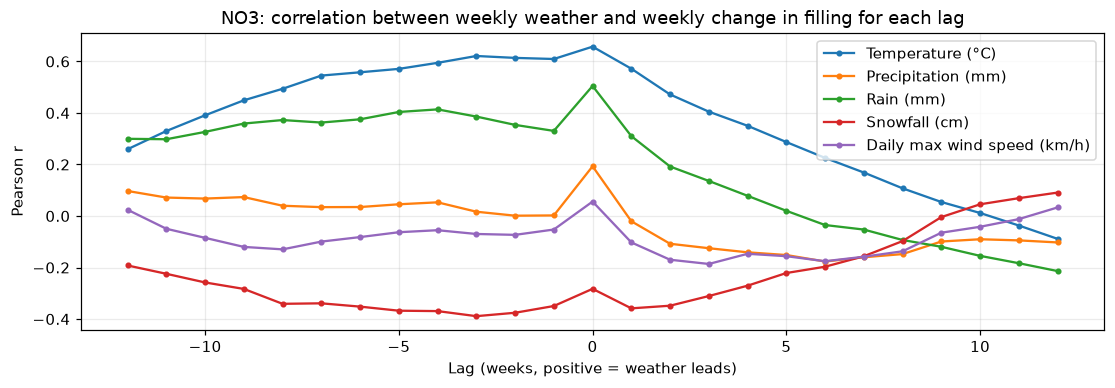

In [16]:
#weekly change in filling for no3 and the weekly weather of the same region
change = (filling * 100).diff().loc[WEATHER_START:]
weather_no3 = weekly_weather_tables["EL 3 (NO3)"]
scans = pd.DataFrame({WEATHER_LABELS[v]: lag_scan(weather_no3[v], change, range(-12, 13)) for v in DAILY_VARIABLES})
#only lags where the weather comes first (lag >= 0) can be used for prediction
leading = scans.loc[0:]
best_lags = pd.DataFrame({"best lag (weeks)": leading.abs().idxmax(),
                          "correlation": [leading[c][leading[c].abs().idxmax()] for c in leading],
                          "correlation at lag 0": scans.loc[0]})
display(best_lags.round(2))

fig, ax = plt.subplots(figsize=(12, 3.5))
scans.plot(ax=ax, marker=".")
ax.set(title="NO3: correlation between weekly weather and weekly change in filling for each lag",
       xlabel="Lag (weeks, positive = weather leads)", ylabel="Pearson r")
plt.show()

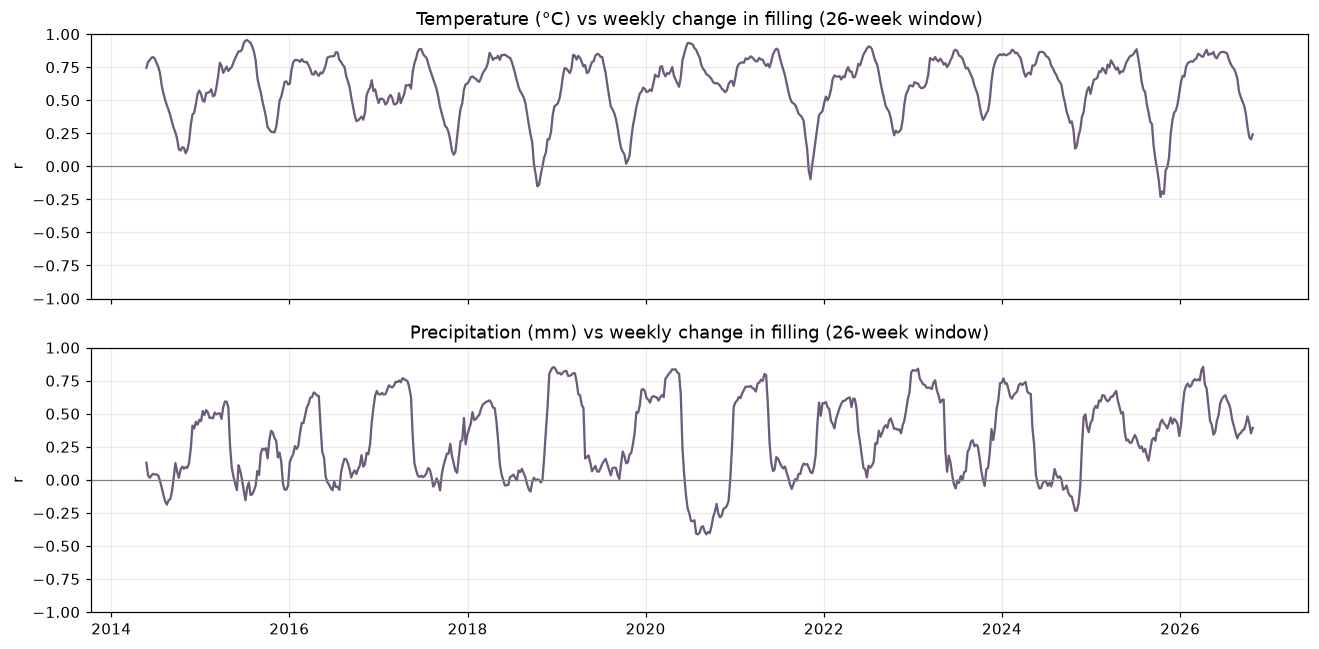

season,winter,spring,summer,autumn
property,,,,
Precipitation (mm),0.82,-0.03,0.03,0.74
Temperature (°C),0.72,0.80,-0.09,0.42


In [17]:
#rolling correlation for temperature and precipitation at lag 0, with a 26 week window
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
seasonal_rows = []
for ax, variable in zip(axes, ["temperature_2m_mean", "precipitation_sum"]):
    frame = sliding_correlation(weather_no3[variable], change, lag=0, window=26)
    ax.plot(frame.index, frame.correlation, color="#6C5B7B")
    ax.axhline(0, color="grey", lw=.8)
    ax.set(ylim=(-1, 1), ylabel="r", title=f"{WEATHER_LABELS[variable]} vs weekly change in filling (26-week window)")
    #correlation within each season (all years together) to see when the relation is strong
    joined = pd.DataFrame({"weather": weather_no3[variable], "change": change}).dropna()
    season = joined.index.month.map({12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
                                     6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn", 11: "autumn"})
    for name, group in joined.groupby(season):
        seasonal_rows.append({"property": WEATHER_LABELS[variable], "season": name, "r": group.weather.corr(group.change)})
plt.tight_layout()
plt.show()
seasonal_table = pd.DataFrame(seasonal_rows).pivot(index="property", columns="season", values="r")[["winter", "spring", "summer", "autumn"]]
display(seasonal_table.round(2))

In [18]:
#findings written from the computed numbers (the wording follows the signs and sizes of the results)
def strength(r):
    r = abs(r)
    return "strong" if r >= .5 else "moderate" if r >= .3 else "weak" if r >= .1 else "almost no"


temperature, precipitation, snow = (WEATHER_LABELS[v] for v in ["temperature_2m_mean", "precipitation_sum", "snowfall_sum"])
seasons = seasonal_table.loc[temperature]
rain_seasons = seasonal_table.loc[precipitation]
lines = [f"**Findings (NO3, {WEATHER_START[:4]}–{WEATHER_END[:4]}).**"]
for label in [temperature, precipitation, snow]:
    lines.append(f"* {label}: {strength(best_lags.loc[label, 'correlation'])} relation to the weekly change in filling, "
                 f"strongest at lag {best_lags.loc[label, 'best lag (weeks)']} weeks (r = {best_lags.loc[label, 'correlation']:.2f}; "
                 f"r = {best_lags.loc[label, 'correlation at lag 0']:.2f} at lag 0).")
lines.append(f"* Temperature by season: r = {seasons['winter']:.2f} (winter), {seasons['spring']:.2f} (spring), "
             f"{seasons['summer']:.2f} (summer) and {seasons['autumn']:.2f} (autumn); strongest in {seasons.abs().idxmax()}. "
             f"Precipitation is strongest in {rain_seasons.abs().idxmax()} (r = {rain_seasons[rain_seasons.abs().idxmax()]:.2f}) "
             f"and weakest in {rain_seasons.abs().idxmin()} (r = {rain_seasons[rain_seasons.abs().idxmin()]:.2f}).")
changes_sign = (seasons.max() > .1) and (seasons.min() < -.1)
lines.append("* The relation " + ("changes sign during the year" if changes_sign else "changes strength during the year") +
             ", which is also visible in the rolling correlation. A linear forecasting model with one constant weather "
             "coefficient can therefore only use part of the information; seasonal interaction terms (for example "
             "temperature in spring), accumulated snowfall since autumn as a snow storage proxy, and weather lagged by "
             "the strongest lag are natural next steps for the predictions.")
display(Markdown("\n".join(lines)))

**Findings (NO3, 2014–2026).**
* Temperature (°C): strong relation to the weekly change in filling, strongest at lag 0 weeks (r = 0.66; r = 0.66 at lag 0).
* Precipitation (mm): weak relation to the weekly change in filling, strongest at lag 0 weeks (r = 0.19; r = 0.19 at lag 0).
* Snowfall (cm): moderate relation to the weekly change in filling, strongest at lag 1 weeks (r = -0.36; r = -0.28 at lag 0).
* Temperature by season: r = 0.72 (winter), 0.80 (spring), -0.09 (summer) and 0.42 (autumn); strongest in spring. Precipitation is strongest in winter (r = 0.82) and weakest in spring (r = -0.03).
* The relation changes strength during the year, which is also visible in the rolling correlation. A linear forecasting model with one constant weather coefficient can therefore only use part of the information; seasonal interaction terms (for example temperature in spring), accumulated snowfall since autumn as a snow storage proxy, and weather lagged by the strongest lag are natural next steps for the predictions.

## 7. Streamlit app

**Refactoring**

- **Theme:** `.streamlit/config.toml` (fjord blue `#1F6F8B` on white, warm accent `#E07A5F`) and the matching Plotly template `ind320` in `src/theme.py`. Each sidebar group has its own accent colour, shown as a band at the top of its pages and on the front page cards.
- **Plotting:** all Matplotlib plots in the app were replaced with Plotly (`src/plots.py`); the analysis functions are called with `plot=False` and the figures are drawn from their numbers. `st.plotly_chart(..., theme=None)` keeps the app template. Native Streamlit charts that remained (the `LineChartColumn` sparklines) are interactive already.
- **Navigation:** grouped pages (Start, Explore, Anomalies, Predict), see section 2.
- **Session state:** the area selection, weather property and map time frame are global; other controls are local.

**New elements**

- **Map and selection:** Folium map (via `streamlit-folium`) with the GeoJSON polygons of the three area types (the Part 3 shapefiles were converted to GeoJSON in `data/regions/`). The area type in the sidebar decides which areas are shown; their outlines are drawn and the areas are coloured transparently by the mean reservoir filling or a weather property (mean or sum over the time frame chosen with a slider). A click on an area selects it for all pages and gives it a thick orange outline.
- **SATV and LOF:** the weather page now has a property selector for both analyses (temperature is the default) and shows the SATV (high-pass part) in its own plot.
- **Weather correlation:** sliding window correlation with property, reservoir variable, years, lag and window.
- **Forecast filling:** model type, all SNARIMAX or lag parameters, learning rate, passes, resolution, interval, exogenous sources and variables, training history and horizon. The training period can be synced with the map time frame (train on the weeks before the frame, forecast the frame) or end at any chosen week. The forecast is animated with Plotly frames (play button and slider).

**Bonus tasks chosen**

- **Confidence intervals:** River quantile loss (`optim.losses.Quantile`) for the lower and upper limits.
- **Waiting time:** spinners for all downloads, a progress bar while the three forecast models train, and `st.cache_data`/`st.cache_resource` for every API and database call (shared between pages).
- **Error handling:** every API and database call is wrapped in `try/except` with a readable message (for example the Open-Meteo quota, MongoDB unavailable, missing hours in a series), and missing values are checked before analyses.
- **Elevation:** a click on the map shows the terrain height of the clicked point from the Open-Meteo elevation API.

## 8. Function and app tests

The test suite (`tests/`) covers the new parts without network access: the Norges Bank CSV parser (separators, decimal commas, unit multipliers), the daily weather request (Oslo days, units), weekly aggregation and the UTC/Oslo day difference, the sliding window correlation on a series with a known lag, the River forecasts (shapes, intervals, bounds, exogenous variables, invalid settings, backtest) and all Streamlit pages with synthetic data (map, correlation, forecast synced with the map time frame).

In [19]:
#run the test suite (no network access and no database writes)
import subprocess
check = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider"],
                       cwd=ROOT, capture_output=True, text=True)
print(check.stdout.replace(str(ROOT), ".")[-1500:])
if check.returncode:
    print(check.stderr[-2000:])

....................................................................     [100%]
68 passed in 12.78s



## 9. Development log

Part 4 finishes the project by adding exchange rates, forecasting and a map, and by reorganising the Streamlit app. All work was done in the branch `part4-development`, which will be merged into `main` with `git merge --no-ff` after the Part 3 peer review and feedback.

I started with the data functions. The Norges Bank API follows the SDMX standard; the CSV format was the easiest to read, but it repeats each dimension as a code and a label and uses unit multipliers, so the parser keeps only the codes and converts every rate to NOK per unit. The timezone investigation showed that the sources use three different conventions: NVE gives Sunday dates for ISO weeks, ENTSO-E gives UTC timestamps, Open-Meteo returns whatever timezone is requested, and Norges Bank gives Norwegian business days. Using the saved NO3 weather from Part 3, I could show that daily precipitation sums change when days are cut in UTC instead of Norwegian time. The solution was to keep UTC where hours matter and convert to Europe/Oslo before every daily or weekly aggregation, so all sources share the NVE weeks.

The forecasting function took most of the time. River learns online in one pass, which is fast but sensitive to the learning rate. SNARIMAX needed seasonal differencing to follow the yearly cycle, and the lag-based model improved a lot when it got the average weekly change for the week of the year as a feature. I tested resolutions, model settings, history lengths and exogenous sources with a backtest of twelve forecast origins in all seasons, and compared with two simple references. Weekly data, ten years of history and weekly weather (with normal weather assumed for the coming weeks) gave the best realistic forecasts, and this setting became the default in Streamlit. Quantile loss gave prediction intervals, but the coverage depends on the learning rate, which I found surprising.

In Streamlit I first drew the navigation sketch and grouped the pages by type of task. All Matplotlib plots were replaced with Plotly, and a common theme was added to both the app and the plots. The map was the most demanding part: Folium gives reliable clicks on polygons, but a click must be remembered so that an old click does not override a later choice in the sidebar. The selected area, weather property and time frame are now stored in the session state, and the forecast page can forecast exactly the time frame chosen on the map. The correlation page made it easy to see that the relation between weather and the weekly change in filling varies strongly through the year (see section 6). For the bonus tasks I chose confidence intervals, waiting-time feedback with caching, error handling and elevation on the map.

Working with the notebook and the app at the same time was useful: every function was first tested in the notebook and with pytest, and then reused unchanged in Streamlit.

## 10. AI usage

Anthropic Claude was used as a coding assistant in Part 4. It helped plan the work from the assignment text, write and refactor the Python modules (Norges Bank client, daily weather, River forecasting, correlation, Plotly figures, Folium map), restructure the Streamlit navigation and theme, write pytest tests and draft this notebook, including the test design for the forecasting settings. It also suggested the timezone checks.

All code was run and tested locally (pytest, the notebook and the running app), and the results, defaults and text were checked against the computed numbers before they were kept.

## 11. Sources

- NVE Magasinstatistikk API: https://biapi.nve.no/magasinstatistikk/swagger/index.html
- Norges Bank open data (API guide): https://www.norges-bank.no/en/topics/Statistics/open-data/
- Open-Meteo Historical Weather API (ERA5, CC BY 4.0): https://open-meteo.com/en/docs/historical-weather-api
- Open-Meteo Elevation API: https://open-meteo.com/en/docs/elevation-api
- ENTSO-E Transparency Platform: https://transparency.entsoe.eu/
- River documentation (SNARIMAX, linear models, quantile loss): https://riverml.xyz/
- Streamlit (navigation, session state, caching): https://docs.streamlit.io/
- Plotly Python: https://plotly.com/python/ ; Folium and streamlit-folium: https://python-visualization.github.io/folium/ , https://folium.streamlit.app/

## Appendix: source code of the new functions

In [20]:
#prints the source code of the main part 4 functions used in this notebook
import inspect
from src.currency import parse_exchange_csv, fetch_exchange_rates
from src.weather import download_daily, weekly_weather
from src.forecast import forecast_filling, LagModel, backtest
from src.correlation import sliding_correlation
for function in [parse_exchange_csv, fetch_exchange_rates, download_daily, weekly_weather,
                 LagModel, forecast_filling, backtest, sliding_correlation]:
    print(inspect.getsource(function))

def parse_exchange_csv(text):
    """turn the norges bank csv answer into a table with one column per currency.

    the separator is detected automatically, and comma decimals (norwegian
    locale) are accepted as well, so the parser works for both locale=en and
    locale=no. returns a dataframe indexed by date with columns such as EUR and USD.
    """
    raw = pd.read_csv(StringIO(text.lstrip('﻿')), sep=None, engine='python', dtype=str)
    #the csv repeats each dimension as a code and a label; the codes are upper case
    needed = {'BASE_CUR', 'TIME_PERIOD', 'OBS_VALUE'}
    if not needed.issubset(raw.columns):
        raise ValueError(f'Unexpected Norges Bank columns: {list(raw.columns)[:8]}')
    values = pd.to_numeric(raw['OBS_VALUE'].str.replace(',', '.', regex=False), errors='coerce')
    #unit_mult says whether the rate is per 1, 100 or more units of the base currency
    if 'UNIT_MULT' in raw.columns:
        multiplier = pd.to_numeric(raw['UNIT_MULT'], errors='coerce').fi